# 06 - Multi-stage Core Formation and Differentiation with Sulfur

This notebook propagates the phase-resolved compositions from primordial differentiation through the post-gas-disk collision histories. For every impact, it separates re-equilibrating and non-re-equilibrating mantle/core inventories, solves the re-equilibrating Fe–Ni–Si–O–S system with the Boujibar S7 sulfur model, and writes the combined product back into the evolving particle state.

It covers:
- Loading the phase-resolved 5 Myr compositions from notebook 03
- Loading the classified impact conditions from notebook 05
- Keeping `S_sil` with silicate material and `S_met` with metal during small/global/partial event splitting
- Solving every post-primordial event with `SulfurKDCalculator` and `ForwardKDOSolverSulfur`
- Auditing Fe, Ni, Si, O, S, MgO, Al2O3, and CaO conservation after every collision
- Recording solver diagnostics and final phase compositions
- Plotting mantle and core sulfur alongside the other major components

Notebook 03 already applied the primordial Rose–Weston S8 model. Every differentiation event in this notebook therefore uses the composition-dependent Boujibar S7 model.

> **Inputs:** `Tables/03_embryo_bulk_composition.csv` and `Tables/05_impact_events_S.xlsx`  
> **Output:** `Tables/06_differentiation_S.xlsx`

Run from the project root or `notebooks/work_flow_S`.

**Mass basis:** Each phase component is stored as mol per 100 g complete body. Multiplying by N-body body mass gives a common-scale collision inventory; the equilibrium solver repartitions only modeled elements. Unmodeled mass follows mass-weighted mergers separately and is checked together with reconstructed modeled mass.


In [1]:
# Sulfur differentiation: thorough physical-root search, then accepted approximate state.
PROJECT_ROOT = None
WORKFLOW_DIR = None
COMPOSITION_FILE = None
IMPACT_FILE = None
METEORITE_FILE = None
OUTPUT_FILE = None
ROOT_SEARCH = 'thorough'       # exact-root audit before approximate fallback
SMALL_CORE_EQ_FRACTION = 0.7
GLOBAL_CORE_EQ_FRACTION = 0.7
GLOBAL_TARGET_MANTLE_FACTOR = 0.05
PARTIAL_CORE_EQ_FRACTION = 0.3
OXYGEN_KD_TOL = 1e-8
OXYGEN_KD_FALLBACK_TOL = 1.5  # dex; nearest-physical-state limit
MASS_RTOL = 1e-5               # N-body collision masses have limited precision
CONSERVATION_RTOL = 1e-8
CONSERVATION_ATOL = 1e-12


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sys
from pathlib import Path

working_dir = Path.cwd()
project_root = (Path(PROJECT_ROOT).expanduser().resolve() if PROJECT_ROOT is not None
                else next((p for p in (working_dir, *working_dir.parents)
                           if (p / "src" / "accrediff").is_dir()), None))
if project_root is None:
    raise RuntimeError("Could not locate the AccreDiff repository root.")
workflow_dir = (Path(WORKFLOW_DIR).expanduser().resolve() if WORKFLOW_DIR is not None
                else project_root / 'kong_2027_backup' / 'work_flow_S')

# Honor WORKFLOW_DIR so isolated batch and manual runs read the same tables.
sys.path.insert(0, str(project_root / 'src'))
import accrediff as ad


# ── Plot style ──────────────────────────────────────────
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.linewidth": 1,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": False,
    "ytick.right": False,
    "figure.dpi": 150,
})

print(f"Project root : {project_root}")
print("Setup complete.")


Project root : /Users/kong/Research/code_zju/AccreDiff
Setup complete.


## 1. Load and Validate Input Data

The composition table stores molar component amounts on one common mass-weighted mixing scale. `S` is an audit total; phase-aware event mixing uses `S_sil` and `S_met` so sulfur is counted exactly once. The impact workbook supplies the event order, participant IDs, P/T conditions, event type, and melt fraction.


In [3]:
composition_file = Path(COMPOSITION_FILE) if COMPOSITION_FILE is not None else workflow_dir / 'Tables' / '03_embryo_bulk_composition.csv'
impact_file = Path(IMPACT_FILE) if IMPACT_FILE is not None else workflow_dir / 'Tables' / '05_impact_events_S.xlsx'
meteorite_file = Path(METEORITE_FILE) if METEORITE_FILE is not None else workflow_dir / 'Tables' / 'Meteorites_composition.csv'

for input_file in (composition_file, impact_file, meteorite_file):
    if not input_file.is_file():
        raise FileNotFoundError(f'Required workflow input not found: {input_file}')

early_components = pd.read_csv(composition_file, index_col=0)
impact_dict = pd.read_excel(impact_file, sheet_name=None)
meteorite_compositions = pd.read_csv(meteorite_file, index_col=0)

if not impact_dict:
    raise ValueError(f'No planet sheets found in {impact_file}.')

required_composition_columns = {
    'i', 'm_e', 'MgO', 'Al2O3', 'CaO', 'FeO', 'NiO', 'SiO2',
    'Fe', 'Ni', 'Si', 'O', 'S', 'S_sil', 'S_met',
    'tracked_mass_fraction', 'untracked_mass_fraction',
}
missing = required_composition_columns - set(early_components.columns)
if missing:
    raise ValueError(f'Early composition table lacks: {sorted(missing)}')
if early_components['i'].duplicated().any():
    raise ValueError('Early composition particle IDs must be unique.')
if not np.allclose(
    early_components['S'],
    early_components['S_sil'] + early_components['S_met'],
    rtol=0.0,
    atol=1e-10,
):
    raise ValueError('Initial S is inconsistent with S_sil + S_met.')

required_event_columns = {
    'Time', 'target_id', 'impactor_id', 'm_target', 'm_impactor',
    'Mass', 'events', 'P_equil', 'T_equil', 'k_mantle',
}
initial_ids = set(early_components['i'].astype(int))
for key, events in impact_dict.items():
    missing = required_event_columns - set(events.columns)
    if missing:
        raise ValueError(f'{key} lacks required event columns: {sorted(missing)}')
    if not events['Time'].is_monotonic_increasing:
        raise ValueError(f'{key} impact events are not in chronological order.')
    event_ids = set(events['target_id'].astype(int)) | set(events['impactor_id'].astype(int))
    missing_ids = event_ids - initial_ids
    if missing_ids:
        raise ValueError(f'{key} references unknown initial particles: {sorted(missing_ids)}')

print(f"Early compositions : {early_components.shape}")
print(f"Planets            : {list(impact_dict)}")


Early compositions : (678, 31)
Planets            : ['planets_1', 'planets_2', 'planets_3', 'planets_4', 'planets_5', 'planets_6']


## 2. Define Phase Components and Model Parameters

`S_sil` follows the mantle fraction and `S_met` follows the core fraction in every event. Total `S` is derived after combining the two phases and never enters event mixing as an independent inventory.


In [4]:
mantle_items = ['MgO', 'Al2O3', 'CaO', 'FeO', 'NiO', 'SiO2', 'S_sil']
core_items = ['Fe', 'Ni', 'Si', 'O', 'S_met']
phase_items = mantle_items + core_items
composition_items = phase_items + ['S']


sulfur_kd_calculator = ad.SulfurKDCalculator()
sulfur_driver = ad.SulfurDifferentiationEventDriver(
    sulfur_kd_calculator=sulfur_kd_calculator,
    root_search=ROOT_SEARCH,
)

print(f"Mantle phase : {mantle_items}")
print(f"Core phase   : {core_items}")
print("Post-primordial sulfur model: Boujibar S7")


Mantle phase : ['MgO', 'Al2O3', 'CaO', 'FeO', 'NiO', 'SiO2', 'S_sil']
Core phase   : ['Fe', 'Ni', 'Si', 'O', 'S_met']
Post-primordial sulfur model: Boujibar S7


## 3. Phase-aware Event Splitting and S7 Differentiation

For each collision, the target and impactor compositions are converted to mass-weighted component amounts. A common helper then separates the re-equilibrating (`bulk_re_eq`) and non-re-equilibrating (`bulk_no_re_eq`) inventories:

| Event | Target mantle in equilibrium | Impactor mantle | Impactor core in equilibrium |
|-------|-------------------------------|-----------------|--------------------------------|
| `small` | none | all | 0.7 |
| `global` | `k_mantle × 0.05` | all | 0.7 |
| `partial` | `k_mantle` | all | 0.3 |

The target core remains outside re-equilibration, following the established workflow. Because the split operates on phase lists, `S_sil` automatically follows mantle material and `S_met` follows metal. The re-equilibrating inventory is collapsed to bulk element totals by `sulfur_params_from_composition`, repartitioned with S7, recombined with the non-equilibrating inventory, and independently audited.

The exact oxygen-KD solution is always attempted first. If extrapolated P/T conditions contain no connected exact root, the closest audited physical state may be retained only when its oxygen-KD mismatch is at most 1.5 dex. This limit covers the workflow's low-pressure events where the currently approved high-pressure Si/O parameter set is extrapolated. Such rows are explicitly marked with `accepted_approximate=True` and `oxygen_converged=False`; the residual remains available for filtering and sensitivity analysis.


In [5]:
def _finite_nonnegative(value, *, label, tolerance=1e-12):
    value = float(value)
    if not np.isfinite(value) or value < -tolerance:
        raise ValueError(f'{label} must be finite and non-negative; got {value}.')
    return max(value, 0.0)


def _absolute_phase_amounts(composition, mass, *, label):
    mass = _finite_nonnegative(mass, label=f'{label} mass')
    if mass <= 0.0:
        raise ValueError(f'{label} mass must be positive.')
    return {
        name: _finite_nonnegative(
            composition[name], label=f'{label} {name}'
        ) * mass
        for name in phase_items
    }


def _add_inventories(*inventories):
    return {
        name: sum(float(inventory[name]) for inventory in inventories)
        for name in phase_items
    }


def _scale_inventory(inventory, fraction):
    fraction = float(fraction)
    if not np.isfinite(fraction) or not 0.0 <= fraction <= 1.0:
        raise ValueError(f'Inventory fraction must lie in [0, 1]; got {fraction}.')
    return {name: float(inventory[name]) * fraction for name in phase_items}


def _phase_subset(inventory, names):
    selected = set(names)
    return {
        name: float(inventory[name]) if name in selected else 0.0
        for name in phase_items
    }


def _elemental_inventory(inventory):
    return {
        'Fe': inventory['FeO'] + inventory['Fe'],
        'Ni': inventory['NiO'] + inventory['Ni'],
        'Si': inventory['SiO2'] + inventory['Si'],
        'O': inventory['FeO'] + inventory['NiO'] + 2.0 * inventory['SiO2'] + inventory['O'],
        'S': inventory['S_sil'] + inventory['S_met'],
        'MgO': inventory['MgO'],
        'Al2O3': inventory['Al2O3'],
        'CaO': inventory['CaO'],
    }


def _assert_inventory_close(before, after, *, context, rtol=CONSERVATION_RTOL):
    residuals = {}
    for name, expected in before.items():
        actual = float(after[name])
        residual = actual - float(expected)
        residuals[name] = residual
        if not np.isclose(actual, expected, rtol=rtol, atol=CONSERVATION_ATOL):
            raise RuntimeError(
                f'{context}: {name} conservation failed; '
                f'before={expected:.16g}, after={actual:.16g}, residual={residual:.3g}.'
            )
    scale = max(max(abs(float(value)) for value in before.values()), CONSERVATION_ATOL)
    return max(abs(value) for value in residuals.values()) / scale


def split_event_inventory(target, impactor, *, mass_target, mass_impactor, event, k_mantle):
    target_total = _absolute_phase_amounts(target, mass_target, label='target')
    impactor_total = _absolute_phase_amounts(impactor, mass_impactor, label='impactor')
    target_mantle = _phase_subset(target_total, mantle_items)
    target_core = _phase_subset(target_total, core_items)
    impactor_mantle = _phase_subset(impactor_total, mantle_items)
    impactor_core = _phase_subset(impactor_total, core_items)

    if event == 'small':
        target_mantle_fraction = 0.0
        impactor_core_fraction = SMALL_CORE_EQ_FRACTION
    elif event == 'global':
        target_mantle_fraction = float(k_mantle) * GLOBAL_TARGET_MANTLE_FACTOR
        impactor_core_fraction = GLOBAL_CORE_EQ_FRACTION
    elif event == 'partial':
        target_mantle_fraction = float(k_mantle)
        impactor_core_fraction = PARTIAL_CORE_EQ_FRACTION
    else:
        raise ValueError(f'Unsupported impact event type: {event!r}.')

    re_eq = _add_inventories(
        impactor_mantle,
        _scale_inventory(impactor_core, impactor_core_fraction),
        _scale_inventory(target_mantle, target_mantle_fraction),
    )
    no_re_eq = _add_inventories(
        target_core,
        _scale_inventory(target_mantle, 1.0 - target_mantle_fraction),
        _scale_inventory(impactor_core, 1.0 - impactor_core_fraction),
    )

    combined_before = _add_inventories(target_total, impactor_total)
    combined_split = _add_inventories(re_eq, no_re_eq)
    _assert_inventory_close(
        _elemental_inventory(combined_before),
        _elemental_inventory(combined_split),
        context=f'{event} event split',
        rtol=1e-12,
    )
    return re_eq, no_re_eq, combined_before


def solve_sulfur_equilibrium(bulk_re_eq, *, pressure, temperature):
    # The equilibrium equations are homogeneous in component amounts.
    # Normalize small collision inventories for numerical conditioning,
    # then restore the original absolute scale after solving.
    equilibrium_scale = sum(float(bulk_re_eq[name]) for name in phase_items)
    if not np.isfinite(equilibrium_scale) or equilibrium_scale <= 0.0:
        raise ValueError('Re-equilibrating inventory must have a positive finite scale.')
    normalized_re_eq = {
        name: float(bulk_re_eq[name]) / equilibrium_scale
        for name in phase_items
    }
    params = ad.sulfur_params_from_composition(
        normalized_re_eq,
        P=pressure,
        T=temperature,
        major_kd_calculator=sulfur_kd_calculator,
    )
    thorough_solver = sulfur_driver.make_solver_factory(
        event_index=1,
        P=pressure,
        T=temperature,
    )(params)
    kd_o_target = sulfur_kd_calculator.get_KD('O', pressure, temperature)

    # Hybrid strategy: the bounded simultaneous solution is the fast primary
    # path. If it is rejected, use the public fast connected-root solver. Only
    # then use its nearest audited physical state under the explicit dex limit.
    result = thorough_solver._solve_direct_constrained_oxygen(
        kd_o_target,
        tol=OXYGEN_KD_TOL,
        x_hint=None,
        sampled_states=(),
    )
    accepted_approximate = False
    solution_strategy = 'simultaneous'
    if result is None:
        fast_solver_kwargs = dict(
            P=pressure,
            T=temperature,
            sulfur_model='boujibar',
            sulfur_kd_calculator=sulfur_kd_calculator,
            root_search='fast',
            sulfur_tol=1e-9,
            coupled_tol=1e-9,
        )
        fast_solver = ad.ForwardKDOSolverSulfur(params, **fast_solver_kwargs)
        try:
            result = fast_solver.solve_x_for_KD_O(
                kd_o_target, tol=OXYGEN_KD_TOL, grid_N=80
            )
            solution_strategy = 'connected_root'
        except ad.OxygenKDNotReachableError as exact_error:
            nearest_solver = ad.ForwardKDOSolverSulfur(
                params,
                allow_nearest=True,
                **fast_solver_kwargs,
            )
            result = nearest_solver.solve_x_for_KD_O(
                kd_o_target, tol=OXYGEN_KD_TOL, grid_N=80
            )
            oxygen_log_residual = result.residuals.get('O_KD_log', result.residual)
            if abs(oxygen_log_residual) > OXYGEN_KD_FALLBACK_TOL:
                raise exact_error
            accepted_approximate = True
            solution_strategy = 'nearest_physical'

    if result.sulfur_model != 'boujibar':
        raise RuntimeError(f'Post-primordial event used {result.sulfur_model!r}, not Boujibar S7.')
    if not (
        result.major_converged
        and result.coupled_converged
        and result.sulfur_converged
        and result.physical_converged
        and (result.oxygen_converged or accepted_approximate)
    ):
        raise RuntimeError(f'Sulfur equilibrium did not converge: {result.failure_reason}')

    equilibrated = {
        'MgO': params.u * equilibrium_scale,
        'Al2O3': params.m / 2.0 * equilibrium_scale,
        'CaO': params.n * equilibrium_scale,
        'FeO': result.x_ * equilibrium_scale,
        'NiO': result.y_ * equilibrium_scale,
        'SiO2': result.z_ * equilibrium_scale,
        'Fe': result.a_ * equilibrium_scale,
        'Ni': result.b_ * equilibrium_scale,
        'Si': result.c_ * equilibrium_scale,
        'O': result.d_ * equilibrium_scale,
        'S_sil': result.S_sil_ * equilibrium_scale,
        'S_met': result.S_met_ * equilibrium_scale,
    }
    diagnostics = {
        'sulfur_model': result.sulfur_model,
        'solution_strategy': solution_strategy,
        'KD_O_target': kd_o_target,
        'KD_O_model': result.KD_O_,
        'O_KD_log_residual': result.residuals.get('O_KD_log', result.residual),
        'D_S_mole': result.D_S_mole,
        'D_S_weight': result.D_S_weight,
        'sulfur_residual': result.sulfur_residual,
        'Ni_residual': result.residuals.get('Ni_equilibrium', np.nan),
        'Si_residual': result.residuals.get('Si_equilibrium', np.nan),
        'overall_converged': bool(result.overall_converged),
        'oxygen_converged': bool(result.oxygen_converged),
        'accepted_approximate': accepted_approximate,
        'accepted': True,
    }
    return equilibrated, diagnostics


def combine_event_result(bulk_no_re_eq, equilibrated, *, total_mass):
    total_mass = _finite_nonnegative(total_mass, label='combined mass')
    if total_mass <= 0.0:
        raise ValueError('Combined mass must be positive.')
    combined_amounts = _add_inventories(bulk_no_re_eq, equilibrated)
    composition = {
        name: _finite_nonnegative(combined_amounts[name], label=f'combined {name}') / total_mass
        for name in phase_items
    }
    composition['S'] = composition['S_sil'] + composition['S_met']
    composition['m_e'] = total_mass
    return composition, combined_amounts


def process_planet_history(events, early_state, *, planet_key):
    state = early_state.copy()
    rows = []

    for event_number, (_, event_row) in enumerate(events.iterrows(), start=1):
        target_id = int(event_row['target_id'])
        impactor_id = int(event_row['impactor_id'])
        context = (
            f'{planet_key} event {event_number} at {float(event_row["Time"]):.6g} Myr '
            f'(target={target_id}, impactor={impactor_id}, type={event_row["events"]})'
        )
        if target_id not in state.index or impactor_id not in state.index:
            raise KeyError(f'{context}: particle state is unavailable.')

        target = state.loc[target_id]
        impactor = state.loc[impactor_id]
        mass_target = float(target['m_e'])
        mass_impactor = float(impactor['m_e'])
        if not np.isclose(mass_target, event_row['m_target'], rtol=MASS_RTOL, atol=1e-12):
            raise RuntimeError(
                f'{context}: target state mass {mass_target} differs from event mass '
                f'{event_row["m_target"]}.'
            )
        if not np.isclose(mass_impactor, event_row['m_impactor'], rtol=MASS_RTOL, atol=1e-12):
            raise RuntimeError(
                f'{context}: impactor state mass {mass_impactor} differs from event mass '
                f'{event_row["m_impactor"]}.'
            )
        total_mass = mass_target + mass_impactor
        # This mass is outside the chemical model. It follows N-body mass
        # merging, never enters the metal-silicate equilibrium solver.
        untracked_inventory_before = (
            mass_target * float(target['untracked_mass_fraction'])
            + mass_impactor * float(impactor['untracked_mass_fraction'])
        )
        if not np.isclose(total_mass, event_row['Mass'], rtol=MASS_RTOL, atol=1e-12):
            raise RuntimeError(f'{context}: combined state mass differs from event Mass.')

        re_eq, no_re_eq, before_amounts = split_event_inventory(
            target,
            impactor,
            mass_target=mass_target,
            mass_impactor=mass_impactor,
            event=event_row['events'],
            k_mantle=event_row['k_mantle'],
        )
        try:
            equilibrated, diagnostics = solve_sulfur_equilibrium(
                re_eq,
                pressure=float(event_row['P_equil']),
                temperature=float(event_row['T_equil']),
            )
        except ad.SulfurSolverError as exc:
            raise type(exc)(
                f'{context}, P={float(event_row["P_equil"]):.6g} GPa, '
                f'T={float(event_row["T_equil"]):.6g} K: {exc}'
            ) from exc
        product, after_amounts = combine_event_result(
            no_re_eq,
            equilibrated,
            total_mass=total_mass,
        )
        product['untracked_mass_fraction'] = untracked_inventory_before / total_mass
        mass_calc = ad.MolarMassCalculator()
        modeled_mass = sum(
            product[name] * mass_calc.molar_mass(name)
            for name in phase_items if name not in {'S_sil', 'S_met'}
        ) + (product['S_sil'] + product['S_met']) * mass_calc.molar_mass('S')
        product['tracked_mass_fraction'] = modeled_mass / 100.0
        if not np.isclose(
            product['tracked_mass_fraction'] + product['untracked_mass_fraction'],
            1.0, rtol=0.0, atol=1e-7,
        ):
            raise RuntimeError(f'{context}: complete-body mass coverage failed.')
        if not np.isclose(
            untracked_inventory_before,
            total_mass * product['untracked_mass_fraction'],
            rtol=CONSERVATION_RTOL, atol=CONSERVATION_ATOL,
        ):
            raise RuntimeError(f'{context}: untracked mass was not conserved.')
        max_conservation_error = _assert_inventory_close(
            _elemental_inventory(before_amounts),
            _elemental_inventory(after_amounts),
            context=context,
        )
        if not np.isclose(product['S'], product['S_sil'] + product['S_met'], rtol=0.0, atol=1e-12):
            raise RuntimeError(f'{context}: sulfur phase closure failed.')

        for name, value in product.items():
            state.loc[target_id, name] = value

        rows.append({
            'Time': float(event_row['Time']),
            'target_id': target_id,
            'impactor_id': impactor_id,
            'event': event_row['events'],
            'P_equil': float(event_row['P_equil']),
            'T_equil': float(event_row['T_equil']),
            'k_mantle': event_row['k_mantle'],
            **product,
            **diagnostics,
            'max_conservation_error': max_conservation_error,
        })

    return pd.DataFrame(rows), state


initial_state = early_components[
    ['i', 'm_e', 'untracked_mass_fraction', 'tracked_mass_fraction'] + composition_items
].copy().set_index('i')
initial_state.index = initial_state.index.astype(int)
df_dict = {}
final_state_dict = {}

for planet_key, events in impact_dict.items():
    history, final_state = process_planet_history(
        events,
        initial_state,
        planet_key=planet_key,
    )
    df_dict[planet_key] = history
    final_state_dict[planet_key] = final_state
    print(f"Processed: {planet_key} ({len(history)} events)")

solver_summary = pd.concat(
    [history.assign(planet=key) for key, history in df_dict.items()],
    ignore_index=True,
)
print("\nSolution strategy counts:")
print(solver_summary.groupby(['planet', 'solution_strategy']).size().unstack(fill_value=0))
print(
    "Approximate physical states: "
    f"{int(solver_summary['accepted_approximate'].sum())} / {len(solver_summary)}; "
    f"maximum |oxygen KD log residual| = "
    f"{solver_summary['O_KD_log_residual'].abs().max():.6g} dex"
)


Processed: planets_1 (127 events)
Processed: planets_2 (55 events)
Processed: planets_3 (119 events)
Processed: planets_4 (45 events)
Processed: planets_5 (19 events)
Processed: planets_6 (12 events)

Solution strategy counts:
solution_strategy  simultaneous
planet                         
planets_1                   127
planets_2                    55
planets_3                   119
planets_4                    45
planets_5                    19
planets_6                    12
Approximate physical states: 0 / 377; maximum |oxygen KD log residual| = 8.99785e-12 dex


## 4. Inspect Final Planet Compositions

The last event in each planet sheet gives its final phase-resolved composition. Total sulfur is retained as an audit column and must equal `S_sil + S_met`.


In [6]:
final_columns = ['Time', 'target_id', 'm_e'] + composition_items
df_planets = pd.concat(
    [history.iloc[[-1]][final_columns] for history in df_dict.values() if not history.empty],
    ignore_index=True,
)

if not np.allclose(
    df_planets['S'], df_planets['S_sil'] + df_planets['S_met'],
    rtol=0.0, atol=1e-10,
):
    raise RuntimeError('Final planet sulfur phase closure failed.')

print(f"Final planets: {len(df_planets)}")
df_planets


Final planets: 6


,Time,target_id,m_e,MgO,Al2O3,CaO,FeO,NiO,SiO2,S_sil,Fe,Ni,Si,O,S_met,S
0,174.488983,316,0.586985,0.602349,0.027442,0.040021,0.059940,0.002594,0.520992,0.000423,0.423724,0.024014,0.020674,0.009653,0.069109,0.069532
1,169.462080,165,0.351987,0.599319,0.026482,0.038604,0.071562,0.002516,0.535943,0.000169,0.408161,0.023913,0.022526,0.010458,0.072604,0.072774
2,173.770604,678,0.711395,0.595902,0.025708,0.037473,0.072429,0.003641,0.550209,0.000368,0.402505,0.022540,0.019107,0.013583,0.077626,0.077994
3,165.347857,1948,0.146963,0.587887,0.023775,0.034754,0.117803,0.001742,0.587627,0.002578,0.333928,0.023083,0.003740,0.004530,0.097450,0.100029
4,146.062388,724,0.038837,0.588844,0.025734,0.037628,0.118623,0.001834,0.534231,0.003148,0.340847,0.023345,0.012892,0.004873,0.097083,0.100231
5,171.473108,1103,0.038831,0.605674,0.027474,0.040308,0.105725,0.001383,0.532971,0.002019,0.353455,0.023612,0.001013,0.002898,0.084483,0.086502


## 5. Visualize Final Phase Compositions

Plot the final common-scale molar component amounts. Squares represent silicate components, including `S_sil`; circles represent metal components, including `S_met`. Marker size scales with final planet mass.


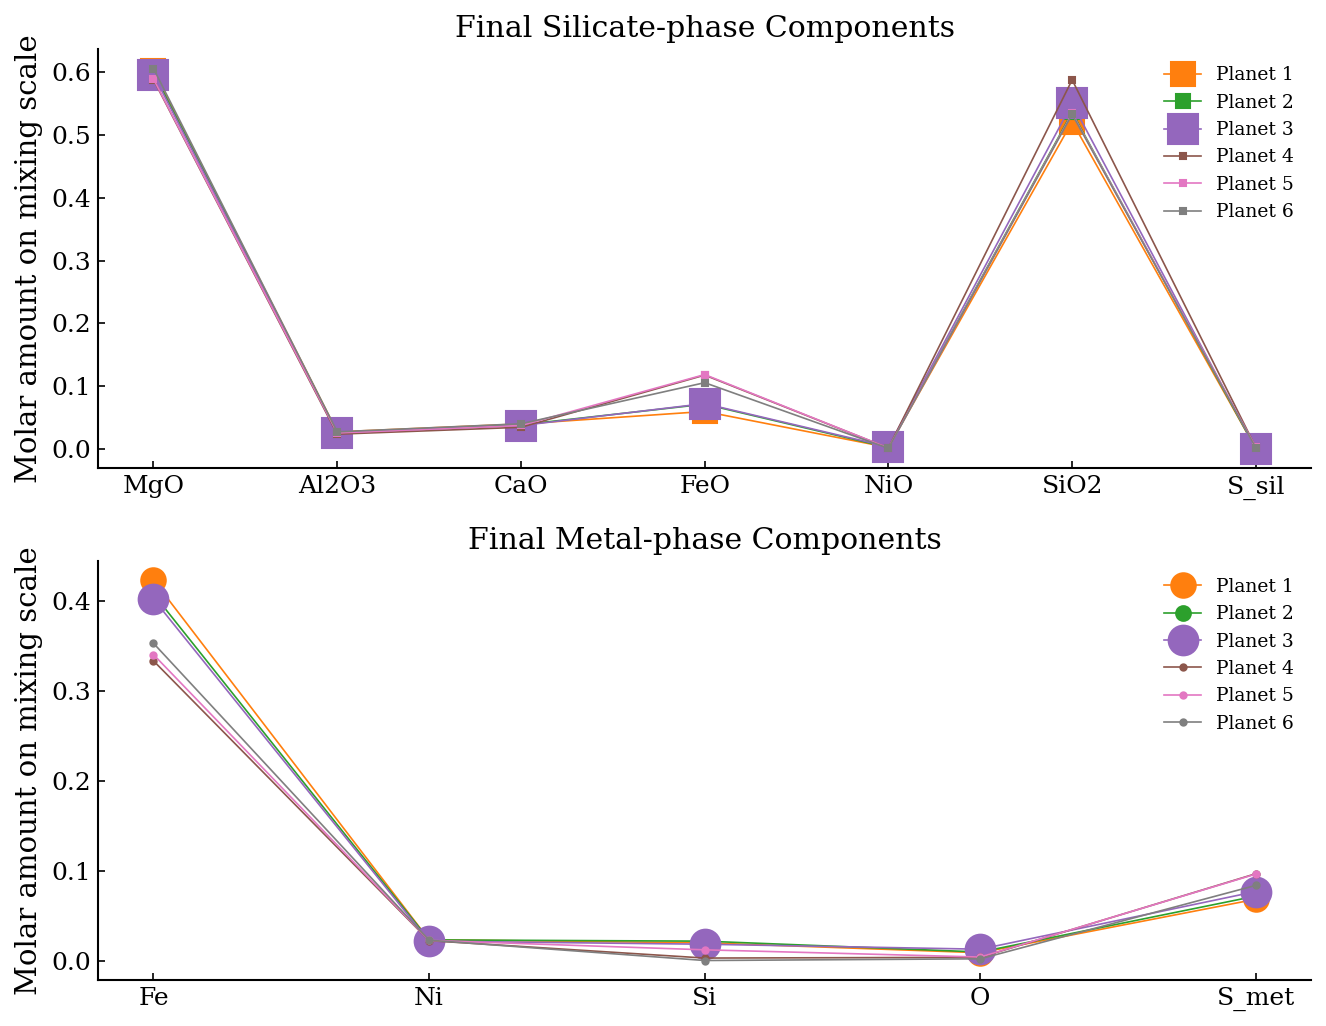

In [7]:
planet_ids = [f'Planet {i+1}' for i in range(len(df_planets))]
cmap = plt.get_cmap('tab10')
color_idx = [i for i in range(10) if i not in (0, 3)]
colors = [cmap(color_idx[i % len(color_idx)]) for i in range(len(df_planets))]

mantle_labels = ['MgO', 'Al2O3', 'CaO', 'FeO', 'NiO', 'SiO2', 'S_sil']
core_labels = ['Fe', 'Ni', 'Si', 'O', 'S_met']

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=False)
for i in range(len(df_planets)):
    mass = df_planets['m_e'].iloc[i]
    axes[0].plot(
        mantle_labels, df_planets[mantle_labels].iloc[i].values,
        marker='s', linewidth=0.8, markersize=max(3.0, 20.0 * mass),
        label=planet_ids[i], color=colors[i],
    )
    axes[1].plot(
        core_labels, df_planets[core_labels].iloc[i].values,
        marker='o', linewidth=0.8, markersize=max(3.0, 20.0 * mass),
        label=planet_ids[i], color=colors[i],
    )

axes[0].set_ylabel('Molar amount on mixing scale')
axes[0].set_title('Final Silicate-phase Components')
axes[1].set_ylabel('Molar amount on mixing scale')
axes[1].set_title('Final Metal-phase Components')
for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(fontsize=9, frameon=False)

plt.tight_layout()
plt.show()


## 6. Normalize to Mg and CI Chondrites

All phase components are first divided by the planet's MgO amount. Ordinary elements use the project CI oxide references. `S_sil` and `S_met` share the bulk CI `S/MgO` value from `Meteorites_composition.csv`; their normalized sum therefore equals normalized total sulfur.


In [8]:
normalization_items = mantle_items + core_items
df_planets_Mg = df_planets[normalization_items].div(df_planets['MgO'].values, axis=0)

CI_bulk_mg = ad.constants.CI_bulk_mg
df_CI = pd.DataFrame([CI_bulk_mg])
ci_sulfur_ref = float(meteorite_compositions.loc['S', 'CI'])
if not np.isfinite(ci_sulfur_ref) or ci_sulfur_ref <= 0.0:
    raise ValueError('CI sulfur reference must be finite and positive.')

mantle_major_keys = ['Al2O3', 'CaO', 'FeO', 'NiO', 'SiO2']
core_major_keys = ['Fe', 'Ni', 'Si']
ci_core_ref = ['FeO', 'NiO', 'SiO2']

normalized_columns = mantle_major_keys + core_major_keys + ['S_sil', 'S_met']
df_planets_CI = df_planets_Mg[normalized_columns].copy()
df_planets_CI[mantle_major_keys] = df_planets_CI[mantle_major_keys].div(
    df_CI[mantle_major_keys].values[0]
)
df_planets_CI[core_major_keys] = df_planets_CI[core_major_keys].div(
    df_CI[ci_core_ref].values[0]
)
df_planets_CI[['S_sil', 'S_met']] = (
    df_planets_CI[['S_sil', 'S_met']] / ci_sulfur_ref
)

normalized_total_s = (df_planets['S'] / df_planets['MgO']) / ci_sulfur_ref
if not np.allclose(
    df_planets_CI['S_sil'] + df_planets_CI['S_met'],
    normalized_total_s,
    rtol=1e-10,
    atol=1e-12,
):
    raise RuntimeError('CI-normalized sulfur phase closure failed.')

print("CI-normalized compositions:")
df_planets_CI


CI-normalized compositions:


,Al2O3,CaO,FeO,NiO,SiO2,Fe,Ni,Si,S_sil,S_met
0,1.148770,1.147422,0.117921,0.093601,0.891297,0.833601,0.866512,0.035368,0.000827,0.135107
1,1.114174,1.112379,0.141496,0.091251,0.921509,0.807041,0.867238,0.038731,0.000333,0.142657
2,1.087814,1.085979,0.144033,0.132813,0.951462,0.800422,0.822138,0.033042,0.000728,0.153398
3,1.019734,1.020906,0.237457,0.064399,1.030022,0.673104,0.853429,0.006555,0.005165,0.195200
4,1.101961,1.103549,0.238720,0.067703,0.934907,0.685934,0.861703,0.022562,0.006295,0.194149
5,1.143792,1.149300,0.206853,0.049640,0.906784,0.691541,0.847334,0.001724,0.003925,0.164256


## 7. Composition Spider Diagram

The CI-normalized spider diagram places both sulfur phases at the same `S` coordinate:

- square: `S_sil`, following the silicate phase;
- circle: `S_met`, following the metal phase.

Both use the same bulk CI sulfur reference. The dashed line at 1 represents the CI abundance relative to Mg.


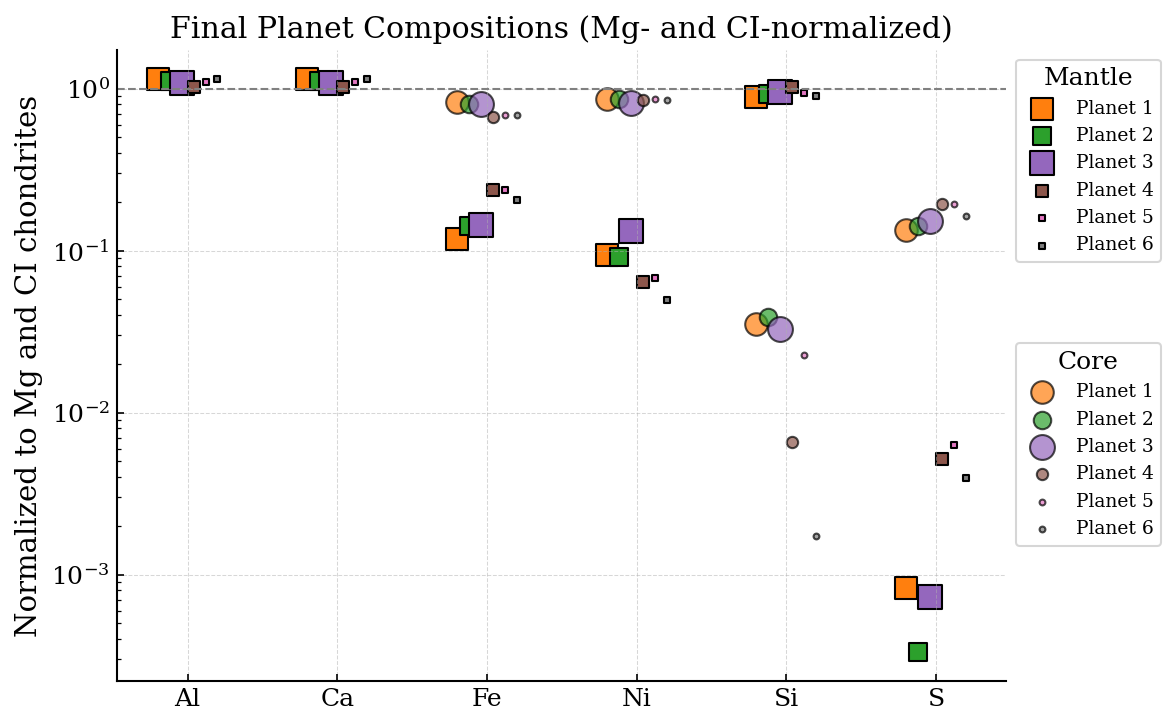

In [9]:
elements = ['Al', 'Ca', 'Fe', 'Ni', 'Si', 'S']
mantle_plot_keys = mantle_major_keys + ['S_sil']
core_plot_keys = core_major_keys + ['S_met']
x_idx = np.arange(len(elements))
core_x_idx = np.array([2, 3, 4, 5])
offsets = np.linspace(-0.2, 0.2, len(df_planets))

fig, ax = plt.subplots(figsize=(8, 5))
legend_groups = {'Mantle': [], 'Core': []}

for i in range(len(df_planets)):
    mass = df_planets['m_e'].iloc[i]
    sc_m = ax.scatter(
        x_idx + offsets[i], df_planets_CI[mantle_plot_keys].iloc[i].values,
        marker='s', s=200 * mass, color=colors[i], edgecolor='k', alpha=1,
    )
    sc_c = ax.scatter(
        core_x_idx + offsets[i], df_planets_CI[core_plot_keys].iloc[i].values,
        marker='o', s=200 * mass, color=colors[i], edgecolor='k', alpha=0.7,
    )
    legend_groups['Mantle'].append(sc_m)
    legend_groups['Core'].append(sc_c)

ax.set_yscale('log')
ax.set_xticks(x_idx)
ax.set_xticklabels(elements)
ax.set_ylabel('Normalized to Mg and CI chondrites')
ax.set_title('Final Planet Compositions (Mg- and CI-normalized)')
ax.axhline(1.0, color='gray', linestyle='--', linewidth=1)
ax.grid(True, which='major', ls='--', lw=0.5, alpha=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

leg1 = ax.legend(
    legend_groups['Mantle'], planet_ids, title='Mantle',
    bbox_to_anchor=(1.0, 1.0), loc='upper left', fontsize=9,
)
ax.add_artist(leg1)
ax.legend(
    legend_groups['Core'], planet_ids, title='Core',
    bbox_to_anchor=(1.0, 0.55), loc='upper left', fontsize=9,
)

plt.tight_layout()
plt.show()


## 8. Export and Verify Results

Export one fully audited differentiation history per final planet. The history includes phase compositions, P/T conditions, the selected sulfur model, partition coefficients, solver residuals, exact/approximate acceptance flags, and the maximum normalized elemental conservation error.


In [10]:
save_dir = workflow_dir / 'Tables'
save_dir.mkdir(parents=True, exist_ok=True)
save_file = Path(OUTPUT_FILE) if OUTPUT_FILE is not None else save_dir / '06_differentiation_S.xlsx'

with pd.ExcelWriter(save_file) as writer:
    for key, history in df_dict.items():
        history.to_excel(writer, sheet_name=key, index=False)

exported_histories = pd.read_excel(save_file, sheet_name=None)
assert list(exported_histories) == list(df_dict)
for key, expected in df_dict.items():
    exported = exported_histories[key]
    if len(exported) != len(expected):
        raise AssertionError(f'Exported row count changed for {key}.')
    if not exported['accepted'].astype(bool).all():
        raise AssertionError(f'{key} contains an unaccepted exported event.')
    if set(exported['sulfur_model']) != {'boujibar'}:
        raise AssertionError(f'{key} contains a non-S7 sulfur model.')
    if not np.allclose(
        exported['tracked_mass_fraction'] + exported['untracked_mass_fraction'],
        1.0, rtol=0.0, atol=1e-7,
    ):
        raise AssertionError(f'{key} complete-body mass coverage changed during export.')
    if not np.allclose(
        exported['S'], exported['S_sil'] + exported['S_met'],
        rtol=0.0, atol=1e-10,
    ):
        raise AssertionError(f'{key} sulfur phase closure changed during export.')

print(f"Saved  : {save_file}")
print(f"Sheets : {list(exported_histories)}")


Saved  : /Users/kong/Research/code_zju/AccreDiff/kong_2027_backup/work_flow_S/Tables/06_differentiation_S.xlsx
Sheets : ['planets_1', 'planets_2', 'planets_3', 'planets_4', 'planets_5', 'planets_6']


## 9. Quick Inspection

Preview the beginning and end of the first planet's audited differentiation history.


In [11]:
first_planet = next(iter(exported_histories))
df_first = exported_histories[first_planet]
print(f"{first_planet} shape: {df_first.shape}")
display(df_first.head())
display(df_first.tail())


planets_1 shape: (127, 38)


,Time,target_id,impactor_id,event,P_equil,T_equil,k_mantle,MgO,Al2O3,CaO,...,D_S_mole,D_S_weight,sulfur_residual,Ni_residual,Si_residual,overall_converged,oxygen_converged,accepted_approximate,accepted,max_conservation_error
0,5.075214,316,868,small,16.857814,2406.406710,NaN,0.610286,0.028821,0.042032,...,586.881367,754.313443,-8.881784e-16,2.919561e-16,-3.552987e-13,True,True,False,True,1.482671e-16
1,5.230915,316,1345,partial,26.703596,2544.564217,0.974899,0.608816,0.028626,0.041706,...,191.768331,183.950494,-3.552714e-15,-9.367092e-16,2.542694e-15,True,True,False,True,1.719722e-16
2,5.543898,2085,2042,small,0.155201,1882.560942,NaN,0.590074,0.021287,0.031576,...,76.767096,95.672846,0.000000e+00,-1.836273e-16,-4.783719e-11,True,True,False,True,7.121332e-17
3,5.606396,316,1548,global,18.795608,2429.294571,0.974899,0.608712,0.028605,0.041675,...,93.619227,88.769291,1.953993e-14,1.346922e-15,2.837880e-14,True,True,False,True,3.430607e-16
4,5.629362,316,958,global,18.795608,2429.294571,0.974899,0.608659,0.028585,0.041647,...,824.958864,967.779905,6.661338e-14,3.377485e-16,5.823403e-14,True,True,False,True,8.540968e-17


,Time,target_id,impactor_id,event,P_equil,T_equil,k_mantle,MgO,Al2O3,CaO,...,D_S_mole,D_S_weight,sulfur_residual,Ni_residual,Si_residual,overall_converged,oxygen_converged,accepted_approximate,accepted,max_conservation_error
122,127.150369,316,2723,small,49.854946,3309.074345,NaN,0.602490,0.027513,0.040119,...,158.010960,247.631381,-3.552714e-15,6.854650e-17,1.022183e-14,True,True,False,True,1.724969e-16
123,135.883237,316,2635,small,49.910937,3310.590804,NaN,0.602422,0.027479,0.040071,...,1027.834199,1388.316562,5.329071e-15,-1.549957e-16,7.753515e-15,True,True,False,True,1.711642e-16
124,139.323022,316,2292,small,50.164093,3317.429242,NaN,0.602402,0.027469,0.040058,...,1024.003978,1381.435381,8.881784e-16,-5.393687e-16,-7.552106e-15,True,True,False,True,2.668614e-18
125,148.371556,316,2155,small,50.235605,3319.355656,NaN,0.602383,0.027459,0.040045,...,1021.623995,1378.413384,-1.776357e-15,3.086877e-16,1.525983e-15,True,True,False,True,1.704139e-16
126,174.488983,316,2480,small,50.308290,3321.311251,NaN,0.602349,0.027442,0.040021,...,1015.911843,1372.567204,3.552714e-15,-7.795025e-17,7.920114e-15,True,True,False,True,0.000000e+00


## 10. Summary

| Step | Operation | Output |
|------|-----------|--------|
| 1 | Load and validate phase-resolved initial states and impact conditions | `early_components`, `impact_dict` |
| 2 | Define mantle/core components and shared sulfur solver | phase lists, `sulfur_driver` |
| 3 | Split each event by phase, solve with S7, and audit conservation | `df_dict` |
| 4 | Collect final phase-resolved planet compositions | `df_planets` |
| 5 | Plot final silicate and metal components | phase composition figure |
| 6 | Normalize to Mg and CI, including a shared CI sulfur reference | `df_planets_CI` |
| 7 | Plot mantle/core sulfur in the CI-normalized spider diagram | spider figure |
| 8 | Export and read back audited histories | `Tables/06_differentiation_S.xlsx` |

All post-primordial events use Boujibar S7. `S` is derived from `S_sil + S_met` and is never mixed as an independent third sulfur inventory. Exact oxygen-KD roots remain distinguishable from explicitly accepted nearest physical states in the exported diagnostics.


### Root audit and extrapolation scenarios

The 76 rows marked `nearest_physical` in the baseline workbook were rechecked independently with the thorough connected-root search. None produced an exact oxygen-KD root under the current model and input state; the reproducible audit is stored in `Tables/06_thorough_root_audit.xlsx`. This is a numerical non-existence result within the configured search domain, not a mathematical proof over all possible model formulations.

Two event-level extrapolation end members are kept outside the baseline history in `Tables/06_extrapolation_scenarios.xlsx`:

- `thorough_nearest_physical`: the closest thorough-search state that retains Ni/Si/S equilibrium and physical/conservation audits but violates the target oxygen KD;
- `phase_preserving_no_repartition`: the incoming re-equilibrating inventory retains its original silicate/metal allocation and no chemical equilibrium is claimed.

These scenarios must be propagated and reported separately in any sensitivity analysis. The fast-nearest baseline, thorough-nearest end member, and phase-preserving end member must not be pooled as equivalent converged solutions.
